## Data Preparation

In [1]:
import torch
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq

import matplotlib.pyplot as plt

from pathlib import Path
from tqdm.autonotebook import tqdm

from hgctsvg.metadata import ProjectMetadata
from hgctsvg.preprocessing import common, singlecell, kidneycancer
from hgctsvg.utils import load_ct_spatial_data

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_crc32c instead.
  from numcodecs.checksum32 import CRC32, Adler32, JenkinsLookup3
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFou

Identify source and results directories

In [2]:
results_dir = Path("hgctsvg_project_files")
project_name = "Human Kidney Cancer Interface"

project_files_dir = results_dir / project_name
project_files_dir.mkdir(parents=True, exist_ok=True)

In [3]:
spotiphy_proj_dir = Path("spotiphy_project_files") / project_name

Load deconvolution results and spatial transcriptomics data.

Spatial transcriptomics data contains spot ids and spot locations, which are requirements for creating hyperedges.

In [4]:
adata_decomp = sc.read_h5ad(spotiphy_proj_dir / "ST_decomposition.h5ad")
adata_st = sc.read_h5ad(spotiphy_proj_dir / "Human Kidney Cancer Interface.h5ad")

The generated cell decomposition data does not yet include the cell locations generated by Spotiphy.
For visualization using Squidpy, we update adata with the generated locations.

In [5]:
adata_decomp = common.add_generated_cell_locations(spotiphy_proj_dir, adata_decomp, adata_st)

Prepared hires segmentation: (1834, 2000), 22430 cells


In [6]:
common_genes = set(adata_st.var_names).intersection(set(adata_decomp.var_names))
len(common_genes)

10827

### Make Project Metadata File

Generate a `ProjectMetadata` object. The `ProjectMetadata` file contains metadata about the project, which is used in several parts of the pipeline:
- `project_folder` - directory of the project.
- `ct_key` - cell type key used by adata objects to indicate the cell type of each cell.
- `ct_list` - list of cell types sorted in lexicographical order.
- `ct_mapping` - mapping of cell type names (`str`) to their positions in the `ct_list` (`int`). `ct_mapping` is important when preparing and accessing data in the pipeline.
- `n_cell_types` - number of cell types in the data.
- `dir_map` - mapping of directories to project subfolders

Creating `ProjectMetadata` requires `ct_key` as an argument, but once created, `ct_key` can also be accessed from the `ProjectMetadata`.

In [7]:
project_metadata = ProjectMetadata.create(project_files_dir, 
                             adata_decomp,
                             'cell_type')
# ct_metadata.ct_key, ct_metadata.ct_list, ct_metadata.ct_mapping, ct_metadata.n_cell_types

In [8]:
project_metadata.dir_map

{'attr_dir': 'attribution',
 'classifier_dir': 'classifiers',
 'clustering_dir': 'clustering',
 'ct_data_dir': 'ct_spatial_data',
 'plot_dir': 'plots'}

## Preprocessing

Preprocess original and decomposed ST data.

### General Preprocessing
Preprocess original ST data using standard preprocessing steps. Also perform HVG selection.

In [9]:
# Preprocessing and HVG detection
n_top_genes = 3000

# filter first before preprocess
adata_decomp = common.filter(adata_decomp, min_genes=20, min_locs=20)
adata_st = common.filter(adata_st, min_genes=20, min_locs=20)

# Preprocess ST data.
# Store unprocessed data to raw.
# Raw data is needed for visualization.
adata_st.raw = adata_st.copy()
sc.pp.highly_variable_genes(adata_st, flavor='seurat_v3', n_top_genes=n_top_genes)
sc.pp.normalize_total(adata_st, target_sum=1e6)
sc.pp.log1p(adata_st)

### Create separate anndata objects for each cell type.

For the decomposed data, we first separate them into different anndata objects per cell type using `preprocessing.singlecell.make_ct_spatial_data`, which also performs preprocessing on each anndata object separately. 

Then, get the top genes per cell type using `preprocessing.singlecell.perform_ct_feature_selection`.

In [10]:
n_features=3000
# singlecell.make_ct_spatial_adata(adata_decomp)
# singlecell.perform_ct_feature_selection(n_features=n_features)

Visualize the resulting anndata objects.

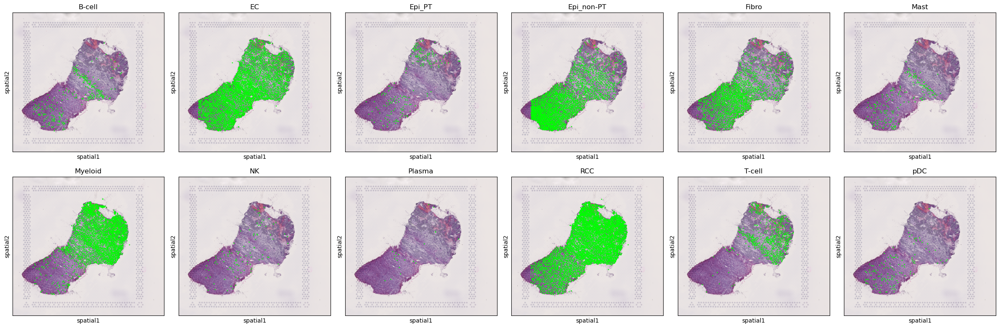

In [11]:
from hgctsvg.visualization import plot_all_ct_decomposition, plot_ct_decomposition
plot_all_ct_decomposition(n_cols=6)

# use this to plot each cell type separately
# plot_ct_decomposition(display=False, show_title=False)

Also visualize the distribution of genes on the original ST anndata object.

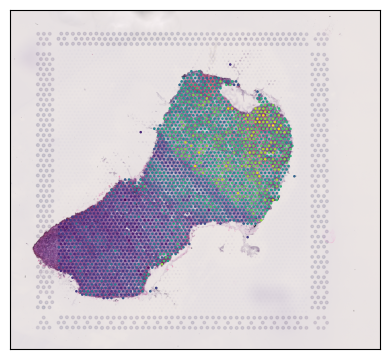

In [12]:
from hgctsvg.visualization import plot_st_gene_counts

plot_st_gene_counts(show_title=False, display=True)

## ML Dataset Creation

Create the Hypergraph Data for the ML pipeline.

In [13]:
hgdata = kidneycancer.create_hypergraph_data(adata_st, n_features=n_features, num_neighbor_spots=7)
hgdata.save()

Also save preprocessed ```adata_decomp``` and ```adata_st```

In [14]:
# save adata_st
adata_st.write_h5ad(project_files_dir / "ST_init.h5ad")

# save adata_decomp
adata_decomp.write_h5ad(project_files_dir / "ST_decomposition.h5ad")

# HGCTSVG Pipeline

For each step of the pipeline, run the following commands:

## I. Embedding Learning

```bash
# Using CUDA
CUDA_VISIBLE_DEVICES=1 hgctsvg train-embedder --project "Human Kidney Cancer Interface" \
--model.model-name HyFiEmbedder --model.input-dim 3000 --model.embedding-dim 50 --model.dropout 0.2 \
--trainer.num_epochs 1000 --trainer.batch_size 22431 --trainer.accelerator cuda
```

```bash
# Using CPU
hgctsvg train-embedder --project "Human Kidney Cancer Interface" \
--model.model-name HyFiEmbedder --model.input-dim 3000 --model.embedding-dim 50 --model.dropout 0.2 \
--trainer.num_epochs 1000 --trainer.batch_size 22431 --trainer.accelerator cpu
```

## II. Embedding Generation

```bash
# Using CUDA
CUDA_VISIBLE_DEVICES=1 hgctsvg make-embedding --project "Human Kidney Cancer Interface" \
--model.model-name HyFiEmbedder --model.input-dim 3000 --model.embedding-dim 50 --model.dropout 0.2 \
--trainer.num_epochs 100 --trainer.batch_size 22431 --trainer.accelerator cuda
```

```bash
# Using CPU
hgctsvg make-embedding --project "Human Kidney Cancer Interface" \
--model.model-name HyFiEmbedder --model.input-dim 3000 --model.embedding-dim 50 --model.dropout 0.2 \
--trainer.num_epochs 100 --trainer.batch_size 22431 --trainer.accelerator cpu
```

## III. Spatial Domain Identification

```bash
hgctsvg compute-spatial-domains --project "Human Kidney Cancer Interface" 
```

## IV. Cell-type Specific Domain Identification

```bash
hgctsvg compute-celltype-spatial-domains --project "Human Kidney Cancer Interface" \
--data.cell-type-key "cell_type"
```

## V. Classifier Training

```bash
# Using CUDA
CUDA_VISIBLE_DEVICES=1 hgctsvg train-celltype-domain-classifiers --project "Human Kidney Cancer Interface" \
--classifier.embedding-dim 50 --classifier.num_layers 3 \
--trainer.num_epochs 1000 --trainer.batch_size 4096 --trainer.accelerator cuda
```

```bash
# Using CPU
hgctsvg train-classifier --project "Human Kidney Cancer Interface" \
--classifier.embedding-dim 50 --classifier.num_layers 3 \
--trainer.num_epochs 1000 --trainer.batch_size 4096 --trainer.accelerator cpu
```

## VI. Spatial Metagene Computation

### A. Compute Metagene Attribution to a Cell Type Spatial Domain
```bash
# Using CUDA
CUDA_VISIBLE_DEVICES=1 hgctsvg compute-cell-embedding-attributions --project "Human Kidney Cancer Interface" \
--cell_type EC \
--classifier.embedding-dim 50 --classifier.num_layers 3 \
--attribution.n_steps 1000 --attribution.accelerator cuda
```

```bash
# Using CPU
hgctsvg compute-cell-embedding-attributions --project "Human Kidney Cancer Interface" \
--cell_type EC \
--classifier.embedding-dim 50 --classifier.num_layers 3 \
--attribution.n_steps 1000 --attribution.accelerator cpu
```

### B. Compute Gene Attribution to Metagene

```bash
CUDA_VISIBLE_DEVICES=0 hgctsvg train-embedder --project "Human Kidney Cancer Interface" --model.model-name CTHGCAEEmbedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --model.dropout 0.2 --trainer.num_epochs 1000 --trainer.batch_size 22431 --trainer.accelerator cuda
CUDA_VISIBLE_DEVICES=0 hgctsvg make-embedding --project "Human Kidney Cancer Interface" --model.model-name CTHGCAEEmbedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --model.dropout 0.2 --trainer.num_epochs 1000 --trainer.batch_size 22431 --trainer.accelerator cuda
hgctsvg compute-spatial-domains --project "Human Kidney Cancer Interface" --clustering.min_cluster_pct -1
hgctsvg compute-celltype-spatial-domains --project "Human Kidney Cancer Interface" --clustering.min_cluster_pct 0.05

CUDA_VISIBLE_DEVICES=0 hgctsvg train-celltype-domain-classifiers --project "Human Kidney Cancer Interface" --classifier.embedding-dim 200 --classifier.num_layers 3 --trainer.num_epochs 1000 --trainer.batch_size 4096 --trainer.accelerator cuda
CUDA_VISIBLE_DEVICES=0 hgctsvg compute-gene-to-celltype-domain-attribution --project "Human Kidney Cancer Interface" --cell-type RCC --model.model-name CTHGCAEEmbedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --classifier.embedding-dim 200 --classifier.num_layers 3 --explainer.n_steps 100 --explainer.batch-size 8192 --explainer.accelerator cuda

CUDA_VISIBLE_DEVICES=0 hgctsvg perform-model-evaluation --project "Human Kidney Cancer Interface" --model.model-name CTHGCAEEmbedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --model.dropout 0.2 --trainer.num_epochs 1000 --trainer.batch_size 22431 --trainer.accelerator cuda --clustering.min_cluster_pct 0.05 --num_runs 10

# CUDA_VISIBLE_DEVICES=0 hgctsvg compute-cell-embedding-attributions --project "Human Kidney Cancer Interface" --classifier.embedding-dim 200 --classifier.num_layers 3 --explainer.n_steps 1000 --explainer.accelerator cuda
# CUDA_VISIBLE_DEVICES=0 hgctsvg compute-metagene-to-region-attribution --project "Human Kidney Cancer Interface" --cell-type EC --region 0 --classifier.embedding-dim 200 --classifier.num_layers 3 --explainer.n_steps 1000 --explainer.accelerator cuda
# CUDA_VISIBLE_DEVICES=0 hgctsvg compute-gene-to-cell-metagene-attribution --project "Human Kidney Cancer Interface" --model.model-name SpatialFusionEmbedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --explainer.n_steps 100 --explainer.batch-size 8192 --explainer.accelerator cuda

```

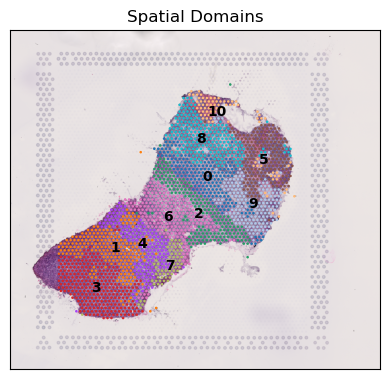

In [384]:
from hgctsvg.visualization import plot_aggr_st_domains

plot_aggr_st_domains(show_title=False)
plot_aggr_st_domains(show_title=True, display=True, save=False)

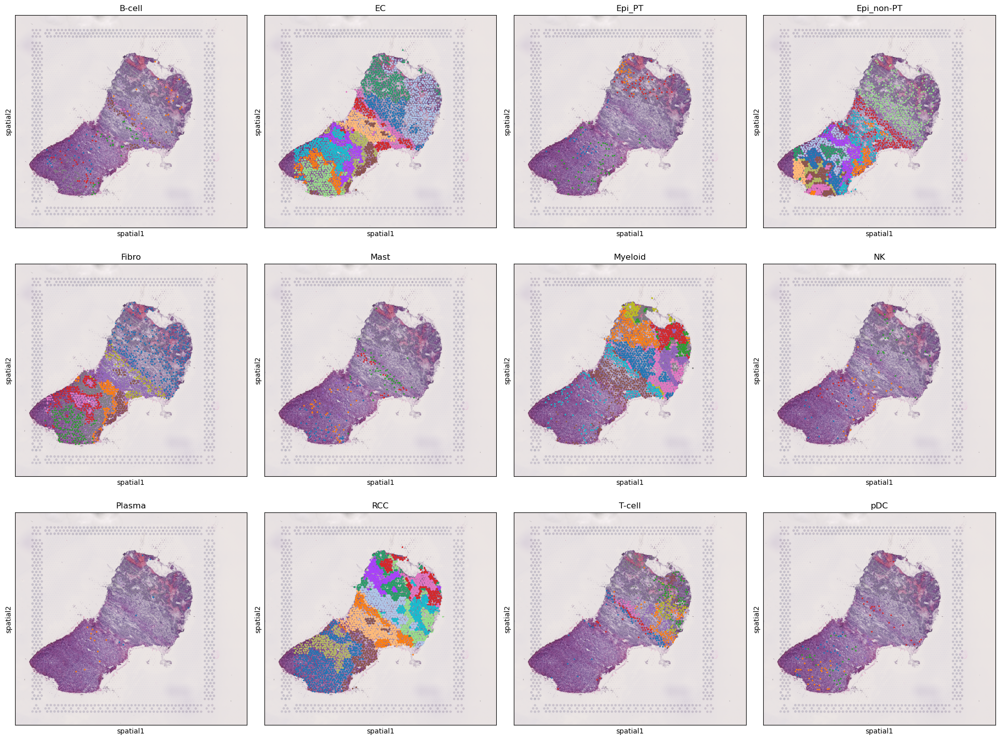

In [385]:
from hgctsvg.visualization import plot_all_ct_domains

plot_all_ct_domains()

In [366]:
from hgctsvg.visualization import plot_ct_domains
plot_ct_domains(show_title=True)

/workspace/HGCTSVG/hgctsvg/src/hgctsvg/visualization/ct.py:150: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
/workspace/HGCTSVG/hgctsvg/src/hgctsvg/visualization/ct.py:150: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
/workspace/HGCTSVG/hgctsvg/src/hgctsvg/visualization/ct.py:150: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
/workspace/HGCTSVG/hgctsvg/src/hgctsvg/visualization/ct.py:150: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
/workspace/HGCTSVG/hgctsvg/src/hgctsvg/visualization/ct.py:150: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
/workspace/HGCTSVG/hgctsvg/src/hgctsvg/visualization/ct.py:150: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
/workspace/HGCTSVG/hgctsvg/src/hgctsvg/visualization/ct.py:150: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
/workspace/HGCTSVG/hgctsvg/src/hgctsvg/vi

In [377]:
adata_aggr.obs['leiden'].astype(int).tolist()

[0,
 1,
 1,
 2,
 2,
 1,
 3,
 4,
 5,
 1,
 1,
 1,
 5,
 2,
 6,
 1,
 3,
 3,
 3,
 5,
 3,
 1,
 5,
 4,
 6,
 1,
 5,
 7,
 4,
 3,
 1,
 2,
 1,
 0,
 2,
 1,
 6,
 4,
 4,
 1,
 1,
 7,
 5,
 3,
 6,
 0,
 6,
 1,
 3,
 4,
 6,
 0,
 2,
 2,
 4,
 0,
 2,
 5,
 3,
 2,
 6,
 6,
 1,
 5,
 7,
 3,
 3,
 1,
 4,
 1,
 2,
 5,
 0,
 3,
 3,
 1,
 4,
 1,
 1,
 6,
 3,
 3,
 2,
 3,
 2,
 7,
 4,
 2,
 2,
 2,
 2,
 7,
 4,
 2,
 4,
 1,
 0,
 1,
 4,
 3,
 1,
 2,
 7,
 4,
 4,
 6,
 4,
 1,
 1,
 7,
 5,
 1,
 5,
 4,
 1,
 5,
 7,
 1,
 6,
 1,
 7,
 7,
 0,
 7,
 5,
 1,
 0,
 3,
 6,
 3,
 6,
 1,
 3,
 1,
 3,
 3,
 4,
 6,
 2,
 1,
 4,
 2,
 1,
 6,
 2,
 3,
 5,
 5,
 7,
 4,
 3,
 5,
 1,
 4,
 2,
 7,
 3,
 7,
 0,
 5,
 5,
 3,
 1,
 1,
 5,
 3,
 5,
 2,
 2,
 7,
 4,
 6,
 1,
 3,
 3,
 3,
 0,
 1,
 1,
 1,
 2,
 3,
 1,
 2,
 1,
 4,
 1,
 1,
 4,
 6,
 3,
 3,
 0,
 2,
 4,
 7,
 4,
 5,
 5,
 2,
 7,
 4,
 4,
 5,
 2,
 7,
 1,
 2,
 6,
 1,
 6,
 1,
 0,
 3,
 1,
 6,
 5,
 5,
 3,
 2,
 6,
 1,
 5,
 0,
 3,
 1,
 4,
 2,
 6,
 1,
 1,
 2,
 3,
 5,
 2,
 3,
 7,
 0,
 7,
 1,
 6,
 1,
 3,
 7,
 7,
 3,
 5,
 7,
 1,
 3,


In [367]:
from hgctsvg.utils import load_aggr_st_data

adata_aggr = load_aggr_st_data()
adata_aggr.obs['leiden'].value_counts()

leiden
3    344
8    255
5    251
7    247
1    201
6    176
2    168
0    159
9    137
4     97
Name: count, dtype: int64

In [408]:
adata_st2 = adata_st[adata_aggr.obs_names]
adata_st2

View of AnnData object with n_obs × n_vars = 2035 × 13707
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region', 'n_genes'
    var: 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-6800STDY12499411', 'mean_counts-6800STDY12499411', 'log1p_mean_counts-6800STDY12499411', 'pct_dropout_by_counts-6800STDY12499411', 'total_counts-6800STDY12499411', 'log1p_total_counts-6800STDY12499411', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'sample_colors', 'spatial', 'hvg', 'log1p'
    obsm: 'spatial'

In [417]:
import torch
embedding = torch.load(project_metadata.project_folder / "hyperedge_embeddings.pth")

nan_mask = torch.isnan(embedding)
nan_rows = torch.any(nan_mask, dim=1)
embedding = embedding[~nan_rows]
embedding = embedding.numpy()
adata_st2.obsm['embedding'] = embedding
adata_st2.obs['leiden_embedding'] = adata_aggr.obs['leiden']

In [418]:
adata_st2

AnnData object with n_obs × n_vars = 2035 × 13707
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region', 'n_genes', 'leiden', 'leiden_embedding'
    var: 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-6800STDY12499411', 'mean_counts-6800STDY12499411', 'log1p_mean_counts-6800STDY12499411', 'pct_dropout_by_counts-6800STDY12499411', 'total_counts-6800STDY12499411', 'log1p_total_counts-6800STDY12499411', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'sample_colors', 'spatial', 'hvg', 'log1p', 'pca', 'neighbors', 'umap', 'leiden_colors', 'embedding', 'leiden'
   

In [419]:
sc.tl.leiden(adata_st2)

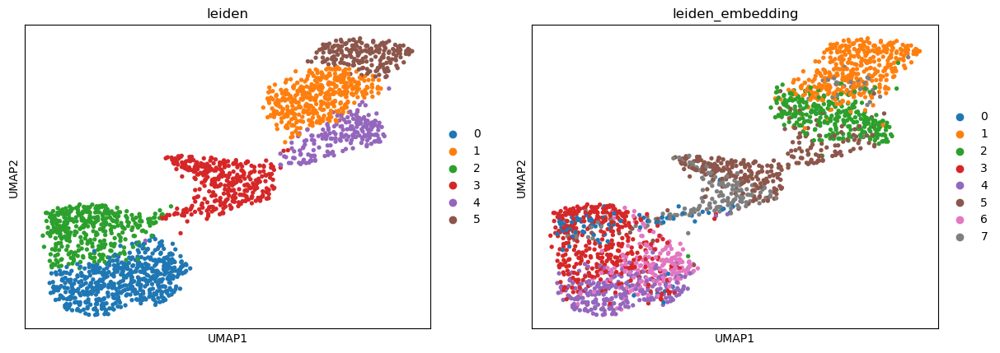

In [420]:
sc.pp.neighbors(adata_st2)
sc.tl.umap(adata_st2)
sc.pl.umap(adata_st2, color=['leiden', 'leiden_embedding'])

In [335]:
sc.tl.rank_genes_groups(adata_aggr, 
                        groupby='leiden',
                        method="wilcoxon",
                        pts=True,
                        use_raw=False)

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/scanpy/tools/_dendrogram.py:138: UserWarning: You’re trying to run this on 10789 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  _choose_representation(adata, use_rep=use_rep, n_pcs=n_pcs)


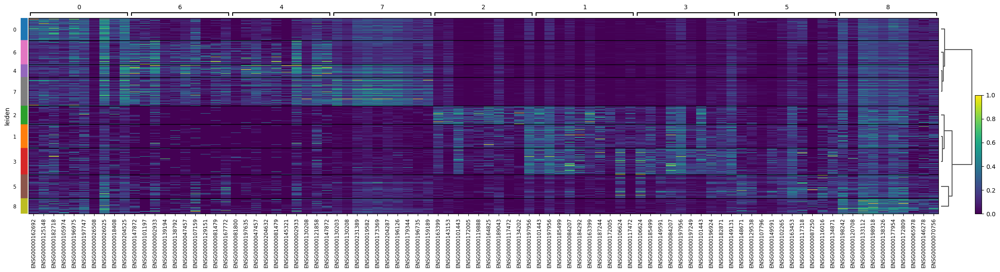

In [336]:
sc.tl.dendrogram(adata_aggr, groupby='leiden')
sc.pl.rank_genes_groups_heatmap(
    adata_aggr,
    n_genes=10,
    standard_scale="var",
    show_gene_labels=True,
)

In [337]:
adata_RCC = load_ct_spatial_data("RCC")
adata_RCC

AnnData object with n_obs × n_vars = 7176 × 10672
    obs: 'cell_type', 'spot_name', 'n_cell', 'location_x', 'location_y', 'library_id', 'segmentation', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'n_genes', 'leiden'
    var: 'SYMBOL', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'hvg_scores', 'spatial_scores', 'combined_scores', 'feature_gene'
    uns: 'cell_count', 'hvg', 'leiden', 'log1p', 'moranI', 'neighbors', 'sample_colors', 'spatial', 'spatial_neighbors'
    obsm: 'cell_nucleus', 'embedding', 'spatial'
    obsp: 'connectivities', 'distances', 'spatial_connectivities', 'spatial_distances'

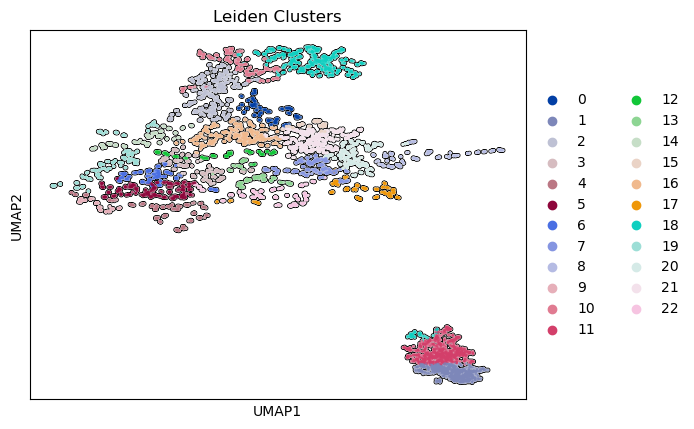

In [338]:
from scipy import sparse

sc.pp.neighbors(adata_RCC, use_rep='embedding', knn=False, method='gauss', key_added='umap')
adata_RCC.obsp['connectivities'] = sparse.csr_matrix(adata_RCC.obsp['connectivities'])
sc.tl.umap(adata_RCC)
sc.pl.umap(adata_RCC, color='leiden', title='Leiden Clusters', add_outline=True)

In [339]:
adata_RCC.obs['leiden'].value_counts()

leiden
11    710
1     657
18    623
2     545
21    532
16    498
5     339
20    328
7     310
10    276
19    258
3     245
6     230
17    217
4     211
22    206
0     182
13    176
8     168
14    162
12    129
15     98
9      76
Name: count, dtype: int64

In [340]:
sc.tl.rank_genes_groups(adata_RCC, 
                        groupby='leiden',
                        method="wilcoxon",
                        pts=True,
                        use_raw=False)

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/scanpy/tools/_rank_genes_groups.py:458: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "names"] = self.var_names[global_indices]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/scanpy/tools/_rank_genes_groups.py:460: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "scores"] = scores[global_indices]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/scanpy/tools/_rank_genes_groups.py:463: PerformanceWarning: DataFrame is highly 

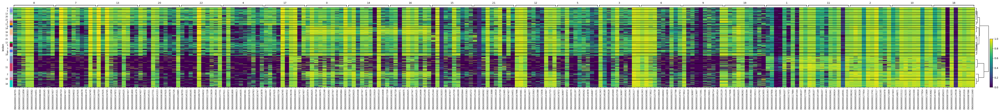

In [341]:
# sc.tl.dendrogram(adata_RCC, groupby='leiden')
sc.tl.dendrogram(adata_RCC, var_names=adata_RCC.var_names[adata_RCC.var['feature_gene']], groupby='leiden')
sc.pl.rank_genes_groups_heatmap(
    adata_RCC,
    n_genes=10,
    standard_scale="var",
    # standard_scale="obs",
    # vmin=adata_RCC.X[adata_RCC.X > 0].min(),
    log=True,
    show_gene_labels=True,
)

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/scanpy/tools/_rank_genes_groups.py:458: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "names"] = self.var_names[global_indices]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/scanpy/tools/_rank_genes_groups.py:460: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "scores"] = scores[global_indices]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/scanpy/tools/_rank_genes_groups.py:463: PerformanceWarning: DataFrame is highly 

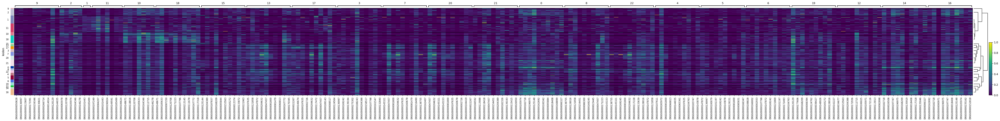

In [342]:
from hgctsvg.pipeline import compute_domain_ct_svgs, create_svg_list
from hgctsvg.visualization import plot_ct_marker_groups_heatmap

top_genes_RCC = compute_domain_ct_svgs("RCC", rank_by='scores')
plot_ct_marker_groups_heatmap(adata_RCC, top_genes_RCC)

In [364]:
top_genes_RCC

{'0':                names     scores  logfoldchanges         pvals     pvals_adj  \
 0    ENSG00000105974  16.525152        2.910204  2.418265e-61  2.580773e-57   
 2    ENSG00000182718  14.849978        1.688074  6.959096e-50  1.856687e-46   
 3    ENSG00000196975  14.656370        2.384897  1.226575e-48  2.618001e-45   
 4    ENSG00000125148  14.528143        1.515622  8.036945e-48  1.429505e-44   
 5    ENSG00000162692  14.457597        2.510249  2.245003e-47  3.422667e-44   
 7    ENSG00000100342  13.283097        2.719441  2.901392e-40  3.096366e-37   
 8    ENSG00000005884  12.905848        2.165765  4.172018e-38  3.710315e-35   
 10   ENSG00000018408  12.010073        2.605003  3.145696e-33  2.397919e-30   
 11   ENSG00000168899  11.715890        1.952022  1.056752e-31  7.518440e-29   
 13   ENSG00000006327  11.528860        3.119127  9.438542e-31  5.925183e-28   
 14   ENSG00000162645  11.471724        2.366741  1.829788e-30  1.084861e-27   
 16   ENSG00000026508  11.359625   

In [343]:
for group in top_genes_RCC:
    print(len(top_genes_RCC[group]))

50
2
5
179
212
208
242
563
106
289
7
7
261
568
326
514
250
671
16
100
318
227
266


In [344]:
top_genes_RCC['0']

,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,pct_nz_reference,pts,pts_rest
0,ENSG00000105974,16.525152,2.910204,2.418265e-61,2.580773e-57,0.978022,0.797827,0.978022,0.797827
2,ENSG00000182718,14.849978,1.688074,6.959096e-50,1.856687e-46,1.000000,0.943809,1.000000,0.943809
3,ENSG00000196975,14.656370,2.384897,1.226575e-48,2.618001e-45,0.983516,0.832142,0.983516,0.832142
4,ENSG00000125148,14.528143,1.515622,8.036945e-48,1.429505e-44,1.000000,0.935373,1.000000,0.935373
5,ENSG00000162692,14.457597,2.510249,2.245003e-47,3.422667e-44,0.972527,0.814269,0.972527,0.814269
7,ENSG00000100342,13.283097,2.719441,2.901392e-40,3.096366e-37,0.928571,0.695739,0.928571,0.695739
8,ENSG00000005884,12.905848,2.165765,4.172018e-38,3.710315e-35,0.967033,0.839291,0.967033,0.839291
10,ENSG00000018408,12.010073,2.605003,3.145696e-33,2.397919e-30,0.901099,0.668859,0.901099,0.668859
11,ENSG00000168899,11.715890,1.952022,1.056752e-31,7.518440e-29,0.967033,0.811982,0.967033,0.811982
13,ENSG00000006327,11.528860,3.119127,9.438542e-31,5.925183e-28,0.906593,0.618387,0.906593,0.618387


In [345]:
top_genes_RCC_merged = create_svg_list(top_genes_RCC)
len(top_genes_RCC_merged)

1528

In [346]:
top_genes_RCC_merged

,scores,adjusted p-vals,region
ENSG00000168899,11.715890,7.518440e-29,0
ENSG00000162645,11.471724,1.084861e-27,0
ENSG00000107438,9.576338,3.155979e-19,0
ENSG00000132507,7.896036,3.614847e-13,0
ENSG00000185043,7.520126,6.083410e-12,0
...,...,...,...
ENSG00000170275,3.378344,5.927206e-03,9
ENSG00000122359,3.028183,1.563315e-02,9
ENSG00000175215,2.898260,2.166964e-02,9
ENSG00000164054,2.711782,3.391251e-02,9


In [347]:
from hgctsvg.pipeline import compute_domain_svgs

top_genes = compute_domain_svgs(rank_by='scores')
top_gene_list = create_svg_list(top_genes)
len(top_gene_list)

1016

In [348]:
top_gene_list

,scores,adjusted p-vals,region
ENSG00000162692,18.249947,2.234548e-70,0
ENSG00000125148,17.226912,5.999501e-63,0
ENSG00000182718,17.190630,8.418658e-63,0
ENSG00000105974,17.020781,1.035711e-61,0
ENSG00000196975,16.245819,3.685608e-56,0
...,...,...,...
ENSG00000196683,7.422744,1.628548e-11,8
ENSG00000009307,6.365195,1.862213e-08,8
ENSG00000185650,6.085916,1.007792e-07,8
ENSG00000181163,5.712445,7.802033e-07,8


In [349]:
for g in sorted(top_genes_RCC_merged['region'].unique()):
    print(g, len(top_genes_RCC_merged[top_genes_RCC_merged['region'] == g]))

0 6
10 1
11 7
12 54
13 137
14 78
15 143
16 176
17 256
18 14
19 17
2 3
20 66
21 74
22 59
3 15
4 65
5 45
6 52
7 167
8 16
9 77


In [350]:
top_genes_RCC_merged[top_genes_RCC_merged['region'] == '0']

,scores,adjusted p-vals,region
ENSG00000168899,11.715890,7.518440e-29,0
ENSG00000162645,11.471724,1.084861e-27,0
ENSG00000107438,9.576338,3.155979e-19,0
ENSG00000132507,7.896036,3.614847e-13,0
ENSG00000185043,7.520126,6.083410e-12,0
ENSG00000184900,7.488704,7.574620e-12,0


In [351]:
adata_decomp.var

,SYMBOL,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts,n_cells
ENSEMBL,,,,,,,,
ENSG00000018869,ZNF582,444,5.502648,1.872209,98.020508,1.234244e+05,11.723392,444
ENSG00000130775,THEMIS2,5051,45.596519,3.841526,77.481052,1.022730e+06,13.837987,5051
ENSG00000134759,ELP2,7723,63.337157,4.164137,65.568435,1.420652e+06,14.166627,7723
ENSG00000090487,SPG21,9276,83.112372,4.432154,58.644672,1.864210e+06,14.438349,9276
ENSG00000171234,UGT2B7,7378,93.922991,4.553066,67.106554,2.106693e+06,14.560630,7378
...,...,...,...,...,...,...,...,...
ENSG00000133069,TMCC2,113,1.898881,1.064325,99.496210,4.259189e+04,10.659443,113
ENSG00000149646,CNBD2,902,5.194585,1.823676,95.978600,1.165145e+05,11.665780,902
ENSG00000177352,CCDC71,861,4.893307,1.773817,96.161391,1.097569e+05,11.606032,861


/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/

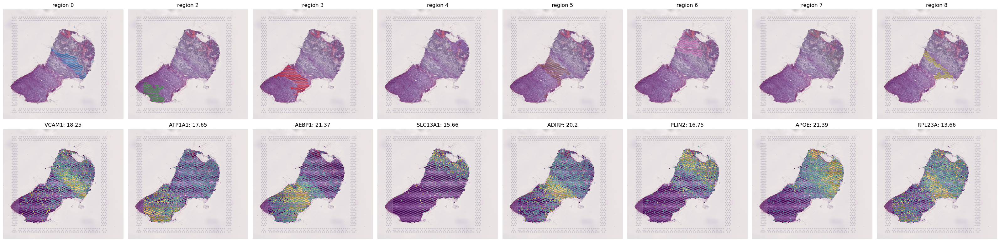

In [352]:
from hgctsvg.visualization import plot_domain_svgs

# groups = adata_RCC.obs['leiden'].unique()
groups = sorted(top_gene_list['region'].unique(), key=lambda r: int(r))
plot_domain_svgs(adata_aggr, top_gene_list, groups, n_cols=len(groups), save=True)

In [358]:
groups

['0',
 '1',
 '10',
 '11',
 '12',
 '13',
 '14',
 '15',
 '16',
 '17',
 '18',
 '19',
 '2',
 '20',
 '21',
 '22',
 '3',
 '4',
 '5',
 '6',
 '7',
 '8',
 '9']

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/

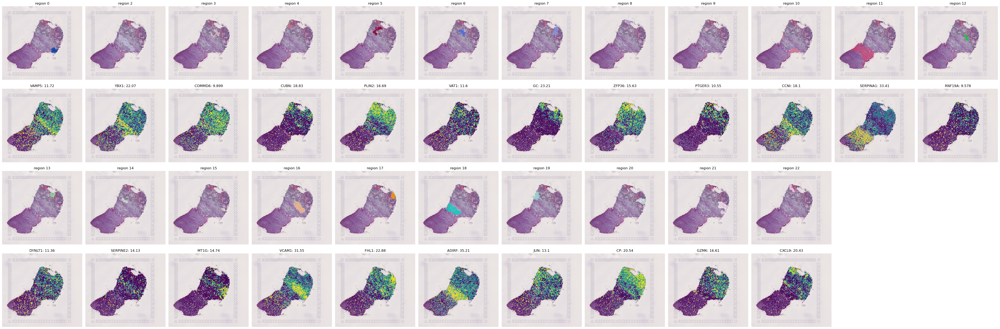

In [360]:
# groups = adata_RCC.obs['leiden'].unique()
groups = sorted(top_genes_RCC_merged['region'].unique(), key=lambda r: int(r))
plot_domain_svgs(adata_RCC, top_genes_RCC_merged, groups, n_cols=12, save=True)

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/

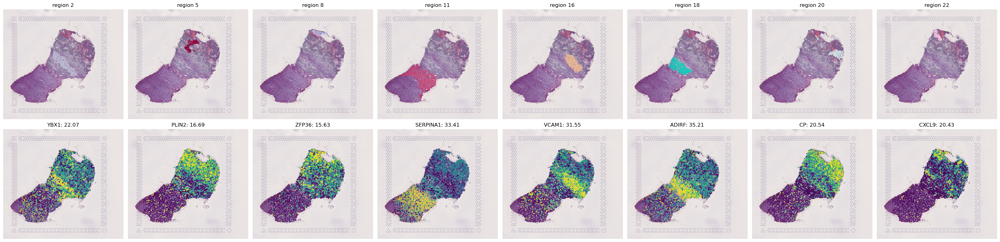

In [363]:
# groups = adata_RCC.obs['leiden'].unique()
groups = ['2','5','8','11','16','18','20','22']
plot_domain_svgs(adata_RCC, top_genes_RCC_merged, groups, n_cols=8, save=True)

In [354]:
rcc_svgs = top_genes_RCC_merged.index
tissue_svgs = top_gene_list.index
union = rcc_svgs.union(tissue_svgs)
intersection = rcc_svgs.intersection(tissue_svgs)
len(rcc_svgs), len(tissue_svgs), len(union), len(intersection), len(intersection)/len(union)

(1528, 1016, 1732, 812, 0.46882217090069284)

In [355]:
top_genes_RCC_merged.loc[rcc_svgs.difference(tissue_svgs)].sort_values("scores",ascending=False)

,scores,adjusted p-vals,region
ENSG00000087250,32.309307,1.381239e-225,18
ENSG00000075945,24.163610,3.821607e-126,16
ENSG00000135333,20.292761,3.975065e-89,16
ENSG00000117472,17.123877,8.759177e-63,17
ENSG00000152952,16.116507,2.290895e-56,16
...,...,...,...
ENSG00000115234,2.574902,4.685055e-02,9
ENSG00000146540,2.470930,4.449817e-02,15
ENSG00000246705,2.461897,4.536815e-02,15
ENSG00000124795,2.390575,3.156754e-02,7


In [356]:
top_gene_list.loc[tissue_svgs.difference(rcc_svgs)].sort_values("scores",ascending=False)

,scores,adjusted p-vals,region
ENSG00000130203,21.390417,1.770311e-97,7
ENSG00000130208,21.173908,8.965010e-96,7
ENSG00000231389,19.274628,3.155086e-79,7
ENSG00000019582,19.085861,8.927146e-78,7
ENSG00000173369,19.036243,1.843645e-77,7
...,...,...,...
ENSG00000108946,2.430010,3.067734e-02,4
ENSG00000165502,2.424814,2.779591e-02,7
ENSG00000088832,2.340937,3.771228e-02,4
ENSG00000147677,2.316186,3.598335e-02,7


/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


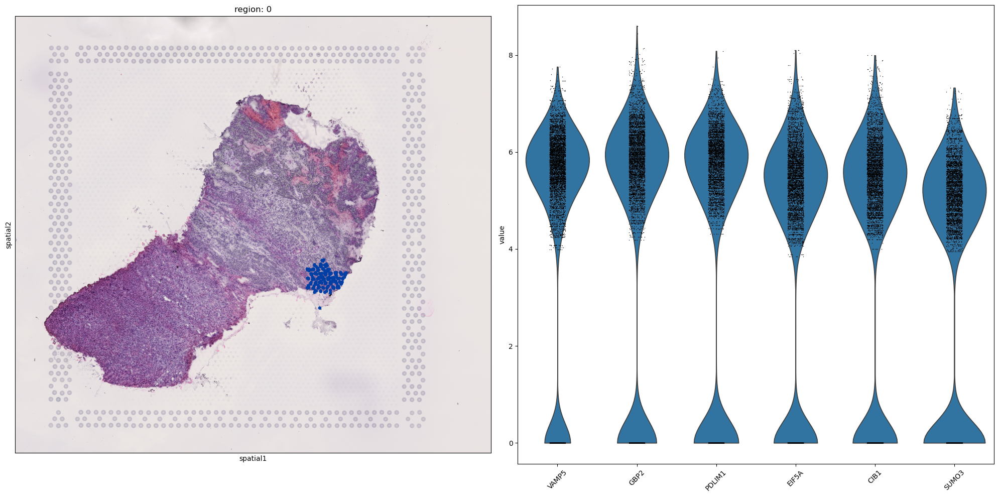

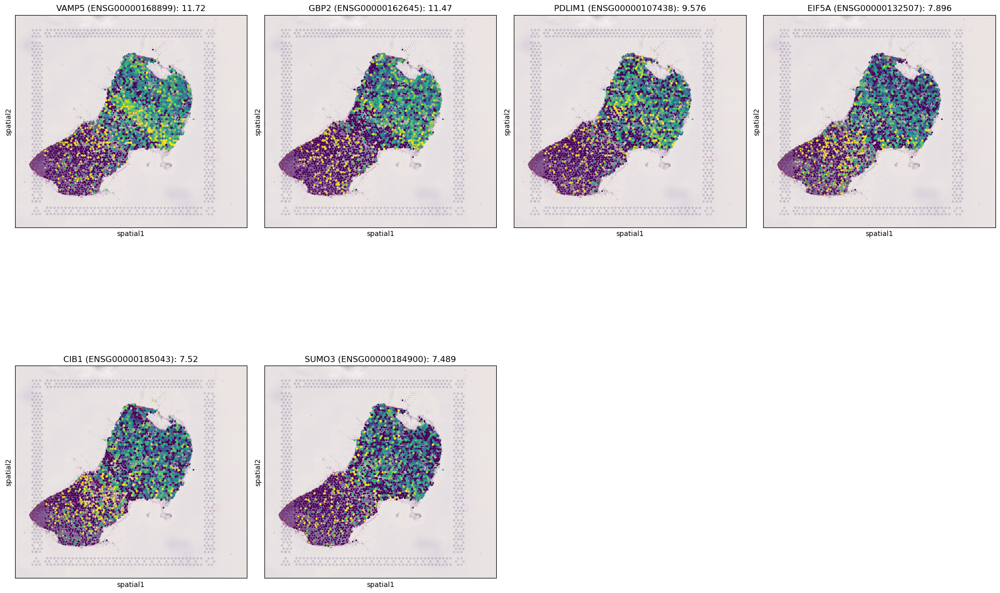

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


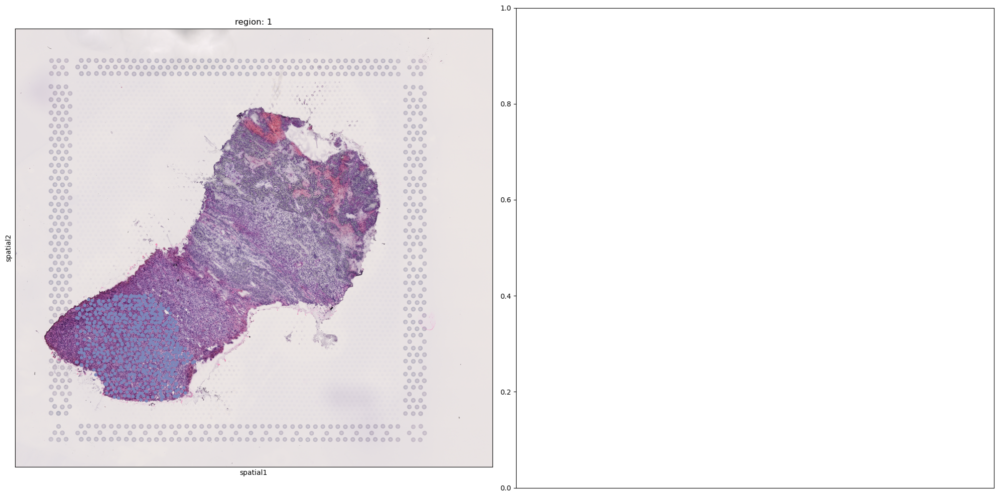

ValueError: Number of rows must be a positive integer, not 0

<Figure size 2000x1500 with 0 Axes>

In [357]:
from hgctsvg.visualization import plot_domain_ct_svgs
groups = sorted(adata_RCC.obs['leiden'].unique())
for g in groups:
    top_genes_RCC_group = top_genes_RCC_merged[top_genes_RCC_merged['region'] == g]
    top_genes_RCC_group = top_genes_RCC_group.sort_values('scores', ascending=False)
    scores = top_genes_RCC_group['scores'].tolist()
    indexes = top_genes_RCC_group.index.tolist()
    plot_domain_ct_svgs(adata_RCC, int(g), scores, indexes, use_raw=False)
    # plot_domain_de_genes(adata_RCC, int(g), top_genes[g]["scores"], top_genes[g]["indexes"])
    # plot_domain_de_genes(adata_RCC, int(g), list(top_genes_RCC[g]["scores"]), list(top_genes_RCC[g]["names"]))

In [ ]:
1834 / 0.18601191, 2000 / 0.18601191

In [ ]:
library_id = list(adata_RCC.uns["spatial"].keys())[0]
adata_RCC.uns["spatial"][library_id]["scalefactors"]["tissue_segmentation_scalef"] = 1

vals = adata_RCC[:,'ENSG00000101443'].X
print(vals.shape)
nz = vals[vals > 0]
vmin = np.percentile(nz, 5)
vmax = np.percentile(nz, 95)
print(vmin, vmax)
sq.pl.spatial_segment(
    adata_RCC,
    seg_cell_id="segmentation",
    color='ENSG00000206503',
    library_key='library_id',
    # figsize=(32,32),
    vmin=vmin,
    vmax=vmax,
    # crop_coord=[(1500,900,1800,1500)]
)

In [ ]:
gene_id = 'ENSG00000000971'
vals = adata_RCC[:,gene_id].X
# remove zeros
nz = vals[vals > 0]
vmin = np.percentile(nz, 5)
vmax = np.percentile(nz, 95)

sq.pl.spatial_scatter(
    adata_RCC,
    color=gene_id,
    use_raw=False,
)

In [ ]:
gene_id = 'ENSG00000000971'
vals = adata_aggr[:,gene_id].X
# remove zeros
nz = vals[vals > 0]
vmin = np.percentile(nz, 5)
vmax = np.percentile(nz, 95)

sq.pl.spatial_scatter(
    adata_aggr,
    color=gene_id,
    use_raw=False,
)

In [ ]:
adata_ENPT = load_ct_spatial_data("Epi_non-PT")
top_genes_ENPT = compute_domain_ct_svgs("Epi_non-PT", rank_by='scores')
plot_ct_marker_groups_heatmap(adata_ENPT, top_genes_ENPT)

In [ ]:
top_genes_ENPT_merged = create_svg_list(top_genes_ENPT)

# groups = adata_RCC.obs['leiden'].unique()
groups = sorted(top_genes_ENPT_merged['region'].unique(), key=lambda r: int(r))
print(len(top_genes_ENPT_merged), len(groups))
plot_domain_svgs(adata_ENPT, top_genes_ENPT_merged, groups, n_cols=len(groups), save=True)

In [ ]:
rcc_svgs = top_genes_RCC_merged.index
tissue_svgs = top_gene_list.index
union = rcc_svgs.union(tissue_svgs)
intersection = rcc_svgs.intersection(tissue_svgs)
len(rcc_svgs), len(tissue_svgs), len(union), len(intersection), len(intersection)/len(union)

In [ ]:
enpt_svgs = top_genes_ENPT_merged.index
union = enpt_svgs.union(tissue_svgs)
intersection = enpt_svgs.intersection(tissue_svgs)
union_ct = rcc_svgs.union(enpt_svgs)
intersection_ct = rcc_svgs.intersection(enpt_svgs)
len(enpt_svgs), len(tissue_svgs), len(union), len(intersection), len(intersection)/len(union), len(union_ct), len(intersection_ct), len(intersection_ct)/len(union_ct)

In [ ]:
groups = sorted(adata_ENPT.obs['leiden'].unique())
for g in groups:
    top_genes_ENPT_group = top_genes_ENPT_merged[top_genes_ENPT_merged['region'] == g]
    top_genes_ENPT_group = top_genes_ENPT_group.sort_values('scores', ascending=False)
    scores = top_genes_ENPT_group['scores'].tolist()
    indexes = top_genes_ENPT_group.index.tolist()
    if len(scores) > 0:
        plot_domain_ct_svgs(adata_ENPT, int(g), scores, indexes, use_raw=False)